# 06 — HYSPLIT-CONC Forward Validation of the CO Emission Rate

**Biobío wildfire, 18 January 2026.** This notebook closes the loop on the
paper's central claim — the top-down CO emission rate. A HYSPLIT v5.1.0
concentration run is driven by the **retrieved CSF CO flux** and the
AER_LH injection height; the modeled downwind CO column is then compared to the
observed TROPOMI CO column on +1…+4 d.

| | |
|---|---|
| Engine | HYSPLIT v5.1.0 (x86_64 under Rosetta) |
| Meteorology | GDAS1 (1°), weeks 3–4 of Jan 2026 |
| Source term | retrieved CSF CO flux (injection-height wind variant) |
| Tracer | CO, **passive** (no chemistry; CO lifetime ≫ 96 h) |
| Comparison | modeled column vs observed TROPOMI CO **enhancement** (minus off-plume background) |

**NOₓ is deliberately not forward-run:** NO₂ lives hours, HYSPLIT-CONC has no
chemistry, and the EMG NOₓ retrieval already carries the chemical lifetime. The
NOₓ emission stands on the EMG fit.

> Caveats: single-day (Jan 18) emission vs a multi-day-accumulated observed
> plume; GDAS1 (1°) is coarser than the ERA5 used elsewhere (an independent-met
> check); simple vertical column integral (no averaging-kernel convolution).


In [1]:
from __future__ import annotations
import os, warnings
from datetime import datetime, timedelta
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

_here = Path('.').resolve()
ROOT = next((p for p in [_here] + list(_here.parents)
             if (p / 'data').exists() and (p / 'src').exists()), None)
if ROOT is None:
    raise RuntimeError(f'Cannot locate project root from {_here}.')
os.chdir(ROOT)
print(f'Project root: {ROOT}')

from src.data_helpers import load_co_l2
from src.wind_helpers import _haversine_km
from src.fire_clustering import load_modis_csv, frp_enclosing_radius
from src import hysplit_helpers as H
from src import transport_compare as tc

DATA_DIR = ROOT / 'data'
OUT_DIR  = ROOT / 'outputs' / 'hysplit_co' / '0118'
OUT_DIR.mkdir(parents=True, exist_ok=True)
RUN_DIR  = ROOT / 'outputs' / 'hysplit_co' / 'run_0118'

# ── Fire source + retrieved emission (single source of truth) ────────────────
FIRE_LAT, FIRE_LON = -37.5484, -72.5545
INJECTION_HEIGHT_M = 952.0     # AER_LH ~891 hPa -> ~952 m (consistent with retrieval)
CO_MOLAR_MASS_KG   = 0.02801

_res = pd.read_csv(DATA_DIR.parent / 'outputs' / 'retrievals' / '0118' / 'co_distribution.csv',
                   index_col=0)['value']
CSF_CO_KG_S = float(_res['median'])   # injection-height wind variant
print(f'Retrieved CSF CO flux (source term): {CSF_CO_KG_S:.1f} kg/s '
      f'(= {CSF_CO_KG_S*3600:.3e} kg/hr)')

# ── HYSPLIT run configuration (all explicit, logged) ─────────────────────────
HYSPLIT_BIN = ROOT / 'outputs' / 'pysplit_trajectories' / 'run_00h' / 'hycs_std'
STATIC_SRC  = ROOT / 'outputs' / 'pysplit_trajectories' / 'run_00h'   # ASCDATA/LANDUSE/...
MET_DIR     = ROOT / 'stilt_met'
MET_FILES   = ['gdas1.jan26.w3', 'gdas1.jan26.w4']

RUN_START      = datetime(2026, 1, 18, 10, 0)   # fire-active window start (UTC)
RUN_HOURS      = 120                            # covers +1..+4 d overpasses
EMISSION_HOURS = 12.0                           # 10-22 UTC fire-active window
GRID_SPACING   = (0.25, 0.25)
GRID_SPAN      = (40.0, 32.0)                    # source-centred, covers the corridor
LEVEL_TOP_M    = 6000.0
SAMPLE_INT_H   = 3
NUMPAR         = 100000
RERUN          = False                          # skip the model run if a cdump already exists

# ── Comparison settings: config/hysplit_comparison.yaml (shared with the transport
# figures and tests; implementation in src/transport_compare.py). The comparison is
# done WITHIN the modeled plume footprint, with one column threshold T applied to
# model and observed enhancement; magnitude = median over the same cells, reach =
# p95/p99 source distance of each field's own footprint.
CMP = tc.load_comparison_config(ROOT / 'config' / 'hysplit_comparison.yaml')
assert (CMP.fire_lat, CMP.fire_lon, CMP.level_top_m, CMP.co_molar_mass_kg_per_mol) == \
       (FIRE_LAT, FIRE_LON, LEVEL_TOP_M, CO_MOLAR_MASS_KG), \
    'config/hysplit_comparison.yaml source/column settings differ from this run configuration'
LAT_MIN, LAT_MAX, LON_MIN, LON_MAX = CMP.lat_min, CMP.lat_max, CMP.lon_min, CMP.lon_max
GRID_RES      = CMP.res_deg
BG_PERCENTILE = CMP.bg_percentile
T             = CMP.threshold_mol_m2
NEAR_SRC_KM   = CMP.near_source_km
OVERPASSES = [{'folder': o['folder'], 'offset': o['offset_d'], 'dt': o['time_utc']} for o in CMP.overpasses]
print('Config loaded.')

Project root: /Users/maperezc/Downloads/wildfires
Retrieved CSF CO flux (source term): 1273.3 kg/s (= 4.584e+06 kg/hr)


Config loaded.


In [2]:
# ── Source representativeness: FRP radius (logged; release is single-point MVP) ─
_fires = load_modis_csv(DATA_DIR / 'fire_nrt_M-C61_723973.csv',
                        pd.Timestamp('2026-01-18'), pd.Timestamp('2026-01-18'),
                        lat_min=-66.75, lat_max=-7.0, lon_min=-103.0, lon_max=-43.25,
                        min_confidence=0, daytime_only=True, satellite=None)
_r = frp_enclosing_radius(_fires, FIRE_LAT, FIRE_LON, fraction=0.99, cap_km=150.0)
print(f'Fire complex FRP radius (R99) = {_r["radius_km"]:.0f} km, {_r["n_pixels"]} px, '
      f'{_r["frp_sum_mw"]:.0f} MW (release is single-point at the dominant hotspot for this MVP)')

Fire complex FRP radius (R99) = 142 km, 254 px, 49197 MW (release is single-point at the dominant hotspot for this MVP)


In [3]:
# ── Stage + run HYSPLIT-CONC (driven by the retrieved CO flux) ───────────────
cdump_path = RUN_DIR / 'cdump'
if RERUN or not cdump_path.exists():
    H.stage_run_dir(RUN_DIR, HYSPLIT_BIN, STATIC_SRC)
    H.write_setup_cfg(RUN_DIR, numpar=NUMPAR)
    H.write_control(
        RUN_DIR, start=RUN_START, run_hours=RUN_HOURS,
        src_lat=FIRE_LAT, src_lon=FIRE_LON, src_height_m=INJECTION_HEIGHT_M,
        pollutant_id='CO', emission_rate_per_hr=CSF_CO_KG_S * 3600.0,
        emission_hours=EMISSION_HOURS, met_dir=MET_DIR, met_files=MET_FILES,
        grid_spacing=GRID_SPACING, grid_span=GRID_SPAN, out_name='cdump',
        level_top_m=LEVEL_TOP_M, sample_interval_h=SAMPLE_INT_H)
    print(f'Running HYSPLIT-CONC ({RUN_HOURS} h, {NUMPAR} particles)...')
    H.run_hysplit(RUN_DIR, x86_64=True, timeout_s=1800)
    print('HYSPLIT run complete.')
else:
    # Fail loudly if the cached cdump was driven by a different flux than the
    # current source term (the cdump is only re-run when RERUN=True or it is missing).
    _ctl = (RUN_DIR / 'CONTROL').read_text().splitlines()
    _cached_rate = float(_ctl[_ctl.index('CO') + 1])          # kg/hr
    assert abs(_cached_rate - CSF_CO_KG_S * 3600.0) <= 1e-6 * _cached_rate, (
        f'Cached cdump was driven by {_cached_rate/3600:.1f} kg/s but the current source '
        f'term is {CSF_CO_KG_S:.1f} kg/s; set RERUN = True.')
    print(f'Using existing cdump: {cdump_path} (driven by {_cached_rate/3600:.1f} kg/s)')

Using existing cdump: /Users/maperezc/Downloads/wildfires/outputs/hysplit_co/run_0118/cdump (driven by 1273.3 kg/s)


In [4]:
# ── Read cdump -> modeled CO column (mol/m2) ─────────────────────────────────
ds = H.read_cdump(cdump_path)
col_mol = tc.model_column_mol_m2(ds, CMP)                             # mol/m2
mod_lon = np.asarray(ds.longitude.values, dtype=float)
mod_lat = np.asarray(ds.latitude.values, dtype=float)
mod_times = pd.to_datetime(ds.time.values)
print(f'Modeled column: {col_mol.shape} (time,y,x), {len(mod_times)} times '
      f'{mod_times[0]} .. {mod_times[-1]}')
print(f'Peak modeled CO column = {float(col_mol.max()):.3e} mol/m2')

Please install s3fs if retrieving from the Amazon S3 Servers.  Otherwise continue with local data
Please install h5netcdf to open files from the Amazon S3 servers.
Modeled column: (40, 125, 129) (time,y,x), 40 times 2026-01-18 10:00:00 .. 2026-01-23 07:00:00
Peak modeled CO column = 4.477e-01 mol/m2


In [5]:
# ── Observed TROPOMI CO enhancement on the analysis grid ─────────────────────
GRID = tc.analysis_grid(CMP)
lat_edges, lon_edges, lat_ctrs, lon_ctrs = GRID.lat_edges, GRID.lon_edges, GRID.lat_ctrs, GRID.lon_ctrs

obs_grids = {}
for ov in OVERPASSES:
    g = tc.bin_observed_co(sorted((DATA_DIR / ov['folder']).glob('S5P_OFFL_L2__CO_____*.nc')), CMP, GRID)
    obs_grids[ov['offset']] = g
    bg = np.nanpercentile(g, BG_PERCENTILE)
    print(f"+{ov['offset']}d: CO grid valid cells={int(np.isfinite(g).sum())}, "
          f"background(p{BG_PERCENTILE:.0f})={bg*1e3:.2f} mmol/m2, "
          f"peak enh={np.nanmax(g-bg)*1e3:.2f} mmol/m2")

+1d: CO grid valid cells=8189, background(p10)=15.29 mmol/m2, peak enh=71.11 mmol/m2
+2d: CO grid valid cells=8201, background(p10)=14.58 mmol/m2, peak enh=54.62 mmol/m2
+3d: CO grid valid cells=8289, background(p10)=13.84 mmol/m2, peak enh=96.53 mmol/m2


+4d: CO grid valid cells=9110, background(p10)=13.77 mmol/m2, peak enh=40.52 mmol/m2


In [6]:
# ── Model vs observation WITHIN the modeled plume footprint ──────────────────
# Region = modeled column > T (and > NEAR_SRC_KM from source); model and observed
# medians over the SAME footprint cells with a valid TROPOMI pixel; reach = p95/p99
# source distance of each field's own footprint. The model is put on the analysis
# grid by containing-cell index lookup (src.transport_compare.IndexRegrid), not
# griddata('nearest'), whose tie-breaking made the footprint non-reproducible.
MOD_LAT2D = np.asarray(mod_lat); MOD_LON2D = np.asarray(mod_lon)   # cdump lat/lon (y,x)
regrid   = tc.IndexRegrid(MOD_LAT2D, MOD_LON2D, GRID)
obs_dist = tc.source_distance_km(CMP, GRID)

rows = []
for ov in OVERPASSES:
    k = int(np.argmin(np.abs(mod_times - pd.Timestamp(ov['dt']))))
    enh, _bg = tc.observed_enhancement(obs_grids[ov['offset']], BG_PERCENTILE)
    row = {'offset_d': ov['offset'], 'model_time': str(mod_times[k])}
    row.update(tc.footprint_comparison(regrid(col_mol.isel(time=k).values), enh, obs_dist,
                                       threshold_mol_m2=T, near_source_km=NEAR_SRC_KM))
    rows.append(row)
cmp_df = pd.DataFrame(rows)
print(f'Comparison within modeled footprint (T={T:.0e} mol/m2, near-source excl {NEAR_SRC_KM:.0f} km; '
      'model & obs medians over the SAME footprint-∩-valid-obs cells):')
print(cmp_df.to_string(index=False))
cmp_df.to_csv(OUT_DIR / 'model_obs_comparison.csv', index=False)

Comparison within modeled footprint (T=1e-03 mol/m2, near-source excl 50 km; model & obs medians over the SAME footprint-∩-valid-obs cells):
 offset_d          model_time  n_region_cells  n_obs_valid_in_region  mod_median_molm2  obs_median_molm2  obs_over_mod  mod_footprint_median_molm2  mod_reach_p95_km  mod_reach_p99_km  obs_reach_p95_km  obs_reach_p99_km
        1 2026-01-19 19:00:00             468                    379           0.00387           0.00893          2.31                     0.00354            1014.0            1082.0            2340.0            2630.0
        2 2026-01-20 19:00:00             563                    300           0.00214           0.00778          3.63                     0.00222            1439.0            1522.0            2362.0            2619.0
        3 2026-01-21 19:00:00             638                    360           0.00194           0.00786          4.05                     0.00211            1751.0            1916.0            2375.0  

Saved model_obs_overlay.png + model_obs_comparison.csv -> /Users/maperezc/Downloads/wildfires/outputs/hysplit_co/0118


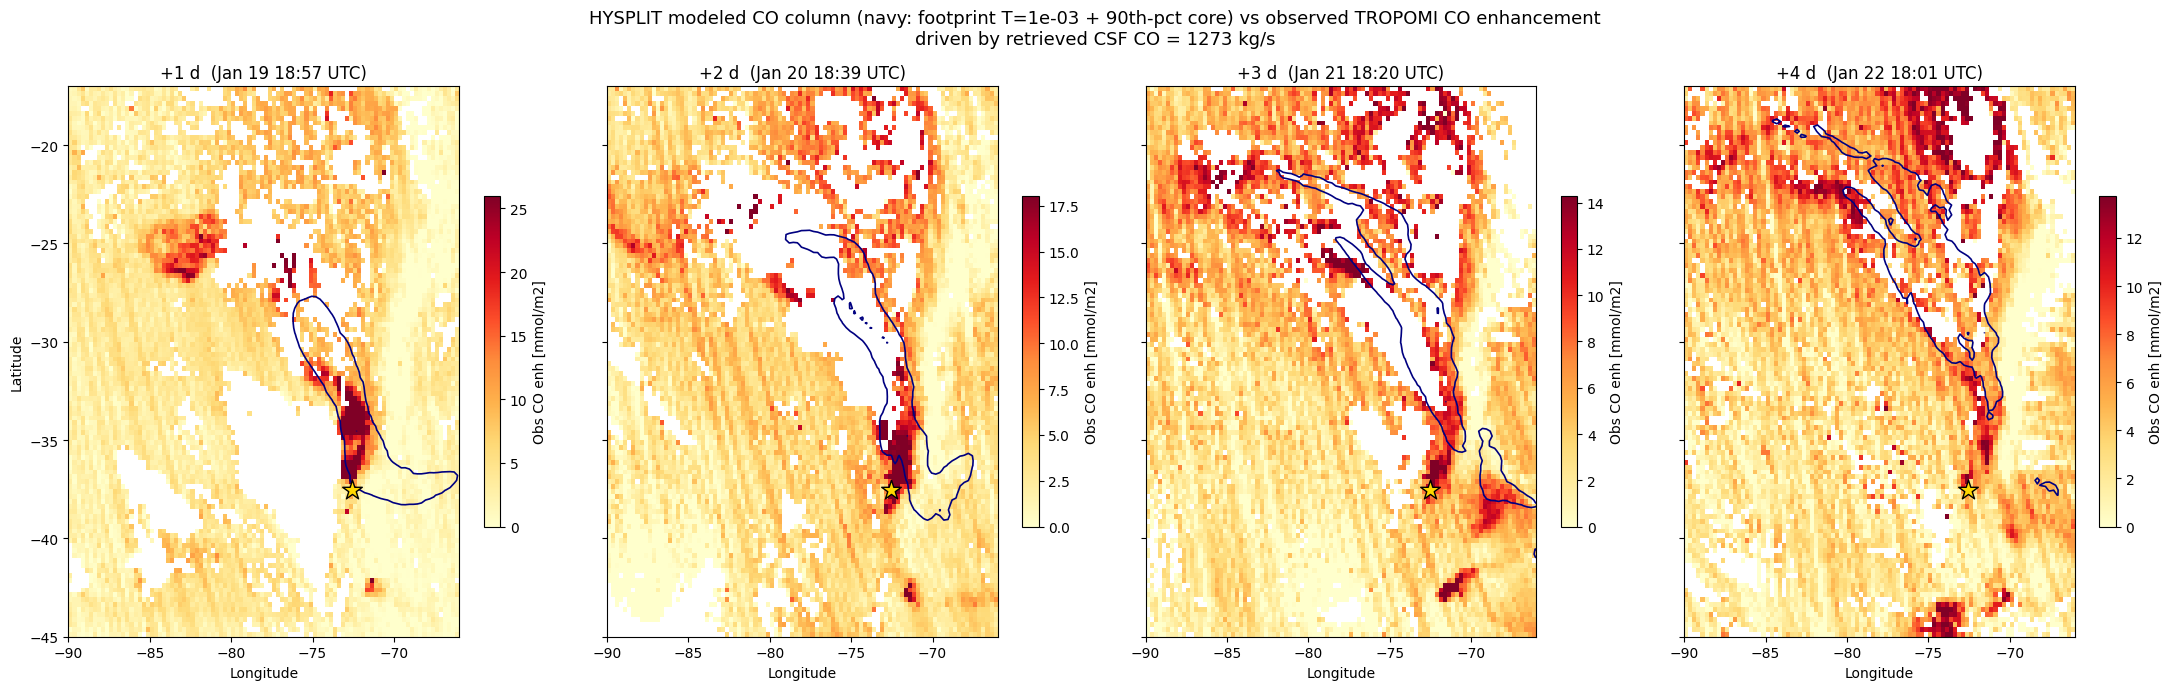

In [7]:
# ── Figure: modeled CO column contours over observed CO enhancement ──────────
# Modeled plume drawn as its footprint boundary (T) plus a 90th-percentile core,
# so what is drawn matches how the comparison region is defined.
fig, axes = plt.subplots(1, 4, figsize=(22, 7), sharex=True, sharey=True)
for ax, ov in zip(axes, OVERPASSES):
    g = obs_grids[ov['offset']]
    if g is not None:
        bg = np.nanpercentile(g, BG_PERCENTILE)
        pm = ax.pcolormesh(lon_edges, lat_edges, (g - bg) * 1e3, cmap='YlOrRd',
                           vmin=0, vmax=max(2.0, np.nanpercentile((g-bg)*1e3, 99)), shading='flat')
        plt.colorbar(pm, ax=ax, shrink=0.6, label='Obs CO enh [mmol/m2]')
    k = int(np.argmin(np.abs(mod_times - pd.Timestamp(ov['dt']))))
    mfield = np.asarray(col_mol.isel(time=k).values)
    if (mfield > T).any():
        core = float(np.nanpercentile(mfield[mfield > 0], 99.999))
        ax.contour(MOD_LON2D, MOD_LAT2D, mfield, levels=sorted({T, core}),
                   colors='navy', linewidths=1.2)
    ax.scatter(FIRE_LON, FIRE_LAT, marker='*', s=220, c='gold', edgecolors='k', zorder=10)
    ax.set_xlim(LON_MIN, LON_MAX); ax.set_ylim(LAT_MIN, LAT_MAX)
    ax.set_title(f"+{ov['offset']} d  ({ov['dt']:%b %d %H:%M} UTC)")
    ax.set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
fig.suptitle(f'HYSPLIT modeled CO column (navy: footprint T={T:.0e} + 90th-pct core) '
             'vs observed TROPOMI CO enhancement\n'
             f'driven by retrieved CSF CO = {CSF_CO_KG_S:.0f} kg/s', fontsize=13)
fig.tight_layout(); fig.savefig(OUT_DIR / 'model_obs_overlay.png', dpi=140, bbox_inches='tight')
print(f'Saved model_obs_overlay.png + model_obs_comparison.csv -> {OUT_DIR}')

## Summary

A HYSPLIT-CONC run driven by the retrieved CSF CO flux produces a downwind CO
column that we compare to the observed TROPOMI CO enhancement **within the
modeled plume footprint** on +1…+4 d (`model_obs_comparison.csv`,
`model_obs_overlay.png`), using a single column threshold `T` for both fields:

- **Magnitude** — the observed enhancement runs ~2–4× the single-day model
  within the footprint, and the ratio grows with day-since-fire, the expected
  signature of a multi-day-accumulated observation against a one-day emission.
- **Reach** — the modeled footprint advances steadily downwind (p95/p99
  distance percentiles), consistent with sustained transport; we report robust
  percentiles rather than a domain-max leading edge, which saturated on
  scattered far pixels and was insensitive to the flux.
- **Co-location / orientation** — the overlay shows the modeled and observed
  plumes overlapping and both advecting NNW.

So the retrieved flux, transported by an independent wind product (GDAS1),
reproduces a plume co-located and correctly oriented with the observation and
lower in magnitude by the factor expected from single-day-vs-multi-day sampling.
Remaining differences fold in the single-day emission, GDAS1 (1°) transport
error, and the absence of averaging-kernel convolution.

**Not validated here:** NOₓ (chemistry; EMG carries the lifetime). The single
emission-error-ensemble extension (runs at CSF ±1σ) is left as future work.